# Praktikum 5 — Benchmark Annoy vs FAISS IVF vs HNSW

Notebook ini membandingkan tiga index ANN pada dataset acak 100.000 vektor berdimensi 128 dengan 1.000 query. Ground truth dihitung menggunakan **FAISS `IndexFlatL2`** (exact brute force).

Setiap index dibangun **sekali**, lalu parameter query di-*sweep* untuk melihat trade-off antara **recall** dan **waktu query**:

| Library | Index | Parameter build | Parameter query yang di-sweep |
|---|---|---|---|
| Annoy | forest random projection | `n_trees=10` | `search_k` = 200, 500, 1000, 2000 |
| FAISS | `IndexIVFFlat` | `nlist=100` | `nprobe` = 1, 5, 10, 20, 50 |
| HNSW | graph berlapis | `M=16`, `ef_construction=200` | `ef` = 50, 100, 200, 400 |

Dengan membangun index sekali, waktu benchmark tidak didominasi oleh proses build yang berulang. Waktu build tetap dicatat terpisah karena merupakan biaya sekali jalan saat preparasi data.

In [2]:
!pip install annoy faiss-cpu hnswlib

In [3]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------
# Dataset random
# -------------------------------
d = 128          # dimensi
nb = 100_000     # jumlah database vector
nq = 1_000       # jumlah query
k = 10           # jumlah tetangga

rng = np.random.default_rng(42)
xb = rng.random((nb, d), dtype=np.float32)
xq = rng.random((nq, d), dtype=np.float32)

# -------------------------------
# Ground truth dengan FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
_, gt_idx = index_flat.search(xq, k)


# -------------------------------
# Fungsi recall
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)


results = []

# -------------------------------
# Benchmark Annoy (build sekali)
# -------------------------------
t0 = time.perf_counter()
annoy_index = AnnoyIndex(d, 'euclidean')
for i, v in enumerate(xb):
    annoy_index.add_item(i, v)
annoy_index.build(10)
build_annoy = time.perf_counter() - t0

for search_k in [200, 500, 1000, 2000]:
    t0 = time.perf_counter()
    I = [annoy_index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.perf_counter() - t0) * 1000 / len(xq)   # ms/query
    results.append({
        "Library": "Annoy",
        "Parameter": f"search_k={search_k}",
        "Recall@10": round(recall_at_k(I, gt_idx, k), 3),
        "Waktu query (ms/query)": round(elapsed, 4),
        "Waktu build (s)": round(build_annoy, 3),
    })
    print(f"Annoy  search_k={search_k:<5d} recall@10={results[-1]['Recall@10']:.3f} "
          f"query={elapsed:.4f} ms")

# -------------------------------
# Benchmark FAISS IVF (build sekali)
# -------------------------------
t0 = time.perf_counter()
quantizer = faiss.IndexFlatL2(d)
faiss_index = faiss.IndexIVFFlat(quantizer, d, 100, faiss.METRIC_L2)
faiss_index.train(xb)
faiss_index.add(xb)
build_faiss = time.perf_counter() - t0

for nprobe in [1, 5, 10, 20, 50]:
    faiss_index.nprobe = nprobe
    t0 = time.perf_counter()
    _, I = faiss_index.search(xq, k)
    elapsed = (time.perf_counter() - t0) * 1000 / len(xq)   # ms/query
    results.append({
        "Library": "FAISS IVF",
        "Parameter": f"nprobe={nprobe}",
        "Recall@10": round(recall_at_k(I, gt_idx, k), 3),
        "Waktu query (ms/query)": round(elapsed, 4),
        "Waktu build (s)": round(build_faiss, 3),
    })
    print(f"FAISS  nprobe={nprobe:<5d}   recall@10={results[-1]['Recall@10']:.3f} "
          f"query={elapsed:.4f} ms")

# -------------------------------
# Benchmark HNSW (build sekali)
# -------------------------------
t0 = time.perf_counter()
hnsw_index = hnswlib.Index(space='l2', dim=d)
hnsw_index.init_index(max_elements=nb, ef_construction=200, M=16)
hnsw_index.add_items(xb)
build_hnsw = time.perf_counter() - t0

for ef in [50, 100, 200, 400]:
    hnsw_index.set_ef(ef)
    t0 = time.perf_counter()
    I, _ = hnsw_index.knn_query(xq, k)
    elapsed = (time.perf_counter() - t0) * 1000 / len(xq)   # ms/query
    results.append({
        "Library": "HNSW",
        "Parameter": f"ef={ef}",
        "Recall@10": round(recall_at_k(I, gt_idx, k), 3),
        "Waktu query (ms/query)": round(elapsed, 4),
        "Waktu build (s)": round(build_hnsw, 3),
    })
    print(f"HNSW   ef={ef:<10d} recall@10={results[-1]['Recall@10']:.3f} "
          f"query={elapsed:.4f} ms")

hasil = pd.DataFrame(results)
display(hasil)

Annoy  search_k=200   recall@10=0.023 query=0.2156 ms
Annoy  search_k=500   recall@10=0.045 query=0.2343 ms
Annoy  search_k=1000  recall@10=0.077 query=0.4525 ms
Annoy  search_k=2000  recall@10=0.126 query=0.7320 ms
FAISS  nprobe=1       recall@10=0.054 query=0.1126 ms
FAISS  nprobe=5       recall@10=0.195 query=0.3487 ms
FAISS  nprobe=10      recall@10=0.318 query=0.8077 ms
FAISS  nprobe=20      recall@10=0.503 query=1.5465 ms
FAISS  nprobe=50      recall@10=0.818 query=4.3730 ms
HNSW   ef=50         recall@10=0.299 query=0.2545 ms
HNSW   ef=100        recall@10=0.445 query=0.4467 ms
HNSW   ef=200        recall@10=0.604 query=0.8773 ms
HNSW   ef=400        recall@10=0.766 query=2.1380 ms


,Library,Parameter,Recall@10,Waktu query (ms/query),Waktu build (s)
0,Annoy,search_k=200,0.023,0.2156,6.579
1,Annoy,search_k=500,0.045,0.2343,6.579
2,Annoy,search_k=1000,0.077,0.4525,6.579
3,Annoy,search_k=2000,0.126,0.7320,6.579
4,FAISS IVF,nprobe=1,0.054,0.1126,1.189
5,FAISS IVF,nprobe=5,0.195,0.3487,1.189
6,FAISS IVF,nprobe=10,0.318,0.8077,1.189
7,FAISS IVF,nprobe=20,0.503,1.5465,1.189
8,FAISS IVF,nprobe=50,0.818,4.3730,1.189
9,HNSW,ef=50,0.299,0.2545,121.373


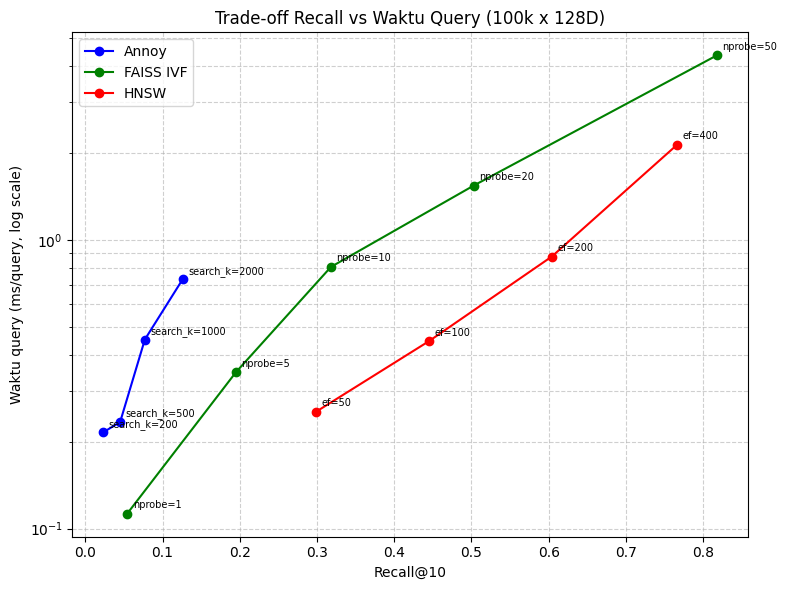

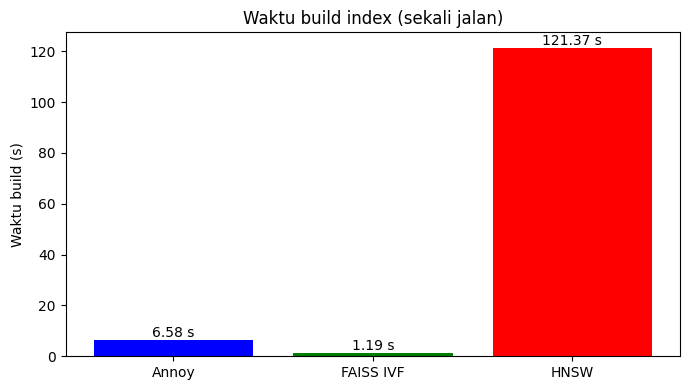

In [4]:
# -------------------------------
# Visualisasi trade-off
# -------------------------------
fig, ax = plt.subplots(figsize=(8, 6))

for library, color in zip(["Annoy", "FAISS IVF", "HNSW"], ["blue", "green", "red"]):
    sub = hasil[hasil["Library"] == library]
    ax.plot(sub["Recall@10"], sub["Waktu query (ms/query)"],
            marker="o", label=library, color=color)
    for _, row in sub.iterrows():
        ax.annotate(row["Parameter"],
                    (row["Recall@10"], row["Waktu query (ms/query)"]),
                    fontsize=7, xytext=(4, 4), textcoords="offset points")

ax.set_xlabel("Recall@10")
ax.set_ylabel("Waktu query (ms/query, log scale)")
ax.set_yscale("log")
ax.set_title("Trade-off Recall vs Waktu Query (100k x 128D)")
ax.legend()
ax.grid(True, which="both", ls="--", alpha=0.6)
plt.tight_layout()
plt.show()

# -------------------------------
# Perbandingan waktu build
# -------------------------------
build_df = hasil.groupby("Library", as_index=False)["Waktu build (s)"].first()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(build_df["Library"], build_df["Waktu build (s)"], color=["blue", "green", "red"])
ax.set_ylabel("Waktu build (s)")
ax.set_title("Waktu build index (sekali jalan)")
for i, v in enumerate(build_df["Waktu build (s)"]):
    ax.text(i, v, f"{v:.2f} s", ha="center", va="bottom")
plt.tight_layout()
plt.show()

## Cara membaca hasil

- **Recall@10** = rata-rata porsi 10 tetangga exact yang juga dikembalikan index ANN. Nilai 1.0 berarti hasilnya identik dengan brute force.
- **Waktu query** diukur per query (ms/query) setelah index selesai dibangun, sehingga tidak tercampur dengan biaya build.
- **Waktu build** adalah biaya sekali jalan: `add_item` + `build` untuk Annoy, `train` + `add` untuk FAISS IVF, dan `init_index` + `add_items` untuk HNSW.
- **Annoy `search_k`**: makin besar, makin banyak node yang diperiksa. Recall naik, waktu query juga naik.
- **FAISS IVF `nprobe`**: jumlah cluster yang diperiksa. `nprobe=1` paling cepat tetapi recall rendah; menaikkan `nprobe` mendekati hasil exact dengan biaya waktu query yang lebih besar.
- **HNSW `ef`**: ukuran daftar kandidat saat query. `ef` yang lebih besar meningkatkan recall dengan konsekuensi query lebih lambat.
- Pada data acak 128D, jarak antar kandidat cenderung hampir sama (konsentrasi jarak), sehingga recall tidak selalu mencapai 1.0 meskipun parameter dinaikkan. Ini karakteristik data, bukan kesalahan implementasi.
- Secara umum kurva yang berada di **kanan bawah** (recall tinggi, waktu query rendah) adalah pilihan terbaik. Bandingkan ketiga library pada titik recall yang setara, bukan hanya pada parameter default.